# 05 - Manejo del desbalance

**Objetivo:** medir si ajustar por el desbalance de clases (3,5% de fraude) mejora el modelo respecto del baseline.

**Enfoque:** mismo LightGBM, mismas variables crudas y mismos cortes temporales que en el baseline. Solo cambia la estrategia de desbalance. Cada configuración se entrena con **3 semillas** y se compara media ± desviación, porque ya vimos que una sola corrida puede engañar (la variación del AUC-PR entre semillas ronda 0,004).

**Estrategias comparadas**
- Sin ajuste (baseline).
- `scale_pos_weight` = raíz de la razón negativos/positivos (ajuste moderado).
- `scale_pos_weight` = razón negativos/positivos (balance completo).
- Submuestreo aleatorio de la clase mayoritaria (se conserva el 20% de los no fraude).

**Por qué no SMOTE:** genera ejemplos sintéticos interpolando entre vecinos, lo que requiere variables numéricas y sin nulos. Acá hay ~430 columnas, 31 categóricas y 214 con más de 50% de nulos; interpolar sobre eso produciría filas sin sentido. Además, los árboles con pesos por clase suelen rendir igual o mejor.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import precision_recall_curve

from src.validation import add_day, temporal_split
from src.evaluate import evaluate

sns.set_theme(style="whitegrid")

## 1. Datos y división temporal

In [2]:
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype("category")

train, valid, test = temporal_split(df)   # test no se usa en este notebook

DROP = ["TransactionID", "TransactionDT", "day", "isFraud"]
features = [c for c in df.columns if c not in DROP]
y_train, y_valid = train["isFraud"], valid["isFraud"]

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"{len(features)} variables | razón negativos/positivos en train: {ratio:.1f}")

432 variables | razón negativos/positivos en train: 27.5


## 2. Configuraciones

In [3]:
params = dict(
    objective="binary", learning_rate=0.05, n_estimators=2000, num_leaves=64,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    n_jobs=-1, verbose=-1,
)

configs = {
    "sin ajuste":              dict(spw=1.0,           neg_frac=1.0),
    "spw = sqrt(razón)":       dict(spw=np.sqrt(ratio), neg_frac=1.0),
    "spw = razón":             dict(spw=ratio,          neg_frac=1.0),
    "submuestreo (20% neg.)":  dict(spw=1.0,           neg_frac=0.2),
}
seeds = [1, 2, 3]

## 3. Entrenamiento
Early stopping sobre validación (sin ponderar). **Tarda varios minutos** (12 entrenamientos). Se guardan las predicciones de la primera semilla para graficar.

In [4]:
def fit_eval(cfg, seed):
    tr = train
    if cfg["neg_frac"] < 1.0:   # submuestreo solo de la clase mayoritaria, solo en train
        neg = train[train["isFraud"] == 0].sample(frac=cfg["neg_frac"], random_state=seed)
        tr = pd.concat([train[train["isFraud"] == 1], neg])

    m = lgb.LGBMClassifier(**{**params, "random_state": seed, "scale_pos_weight": cfg["spw"]})
    m.fit(
        tr[features], tr["isFraud"],
        eval_set=[(valid[features], y_valid)], eval_metric="auc",
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    p = m.predict_proba(valid[features])[:, 1]
    res = evaluate(y_valid, p)
    res["mejor_iteracion"] = m.best_iteration_
    return res, p

runs, preds = {}, {}
for name, cfg in configs.items():
    out = [fit_eval(cfg, s) for s in seeds]
    runs[name] = [r for r, _ in out]
    preds[name] = out[0][1]          # predicciones de la primera semilla
    print(f"listo: {name}")

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


listo: sin ajuste


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


listo: spw = sqrt(razón)


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


listo: spw = razón


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


listo: submuestreo (20% neg.)


## 4. Resultados (media ± desviación sobre 3 semillas)

In [5]:
metrics = ["auc_pr", "auc_roc", "recall@prec50", "recall@prec80", "mejor_iteracion"]
summary = pd.DataFrame({
    name: {m: f"{np.mean([r[m] for r in res]):.4f} ± {np.std([r[m] for r in res]):.4f}" for m in metrics}
    for name, res in runs.items()
})
summary

,sin ajuste,spw = sqrt(razón),spw = razón,submuestreo (20% neg.)
auc_pr,0.6172 ± 0.0040,0.5936 ± 0.0014,0.2920 ± 0.0132,0.5960 ± 0.0070
auc_roc,0.9276 ± 0.0004,0.9249 ± 0.0007,0.8391 ± 0.0029,0.9267 ± 0.0020
recall@prec50,0.6215 ± 0.0049,0.5869 ± 0.0037,0.2305 ± 0.0200,0.5885 ± 0.0040
recall@prec80,0.4326 ± 0.0068,0.4043 ± 0.0021,0.0000 ± 0.0000,0.4099 ± 0.0086
mejor_iteracion,532.3333 ± 77.2111,397.3333 ± 39.2032,1.0000 ± 0.0000,655.0000 ± 247.9207


## 5. Curvas precisión-recall (semilla 1)

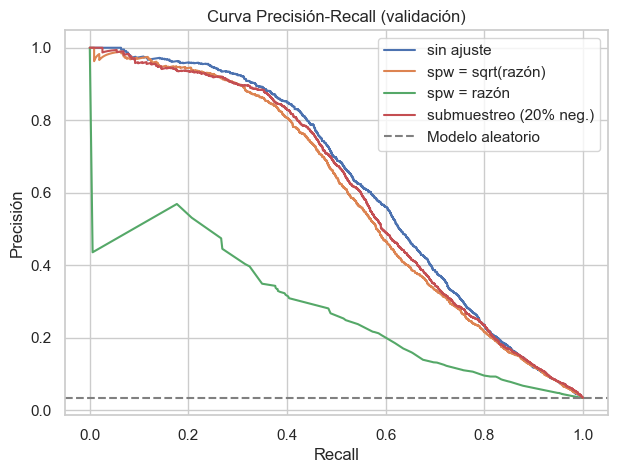

In [6]:
plt.figure(figsize=(7, 5))
for name, p in preds.items():
    prec, rec, _ = precision_recall_curve(y_valid, p)
    plt.plot(rec, prec, label=name)
plt.axhline(y_valid.mean(), color="gray", linestyle="--", label="Modelo aleatorio")
plt.xlabel("Recall"); plt.ylabel("Precisión")
plt.title("Curva Precisión-Recall (validación)"); plt.legend(); plt.show()

## 6. Conclusiones

**Resultado:** ninguna estrategia de desbalance supera al baseline sin ajuste (AUC-PR 0,6172 ± 0,0040).
- `scale_pos_weight` = sqrt(razón): 0,5936 ± 0,0014
- Submuestreo (20% de negativos): 0,5960 ± 0,0070
- `scale_pos_weight` = razón: 0,2920 ± 0,0132; el early stopping detuvo el entrenamiento en la iteración 1, por lo que esta configuración no se evaluó en condiciones comparables.

Las caídas de ~0,02 en AUC-PR de las dos primeras superan la variación entre semillas.

**Hipótesis (no verificada):** LightGBM ya maneja bien el desbalance al optimizar el ranking; reponderar o submuestrear distorsiona la señal sin agregar información.

**Decisión:** se mantiene el modelo sin ajuste. Además, así las probabilidades quedan sin distorsionar, lo que simplifica la elección del umbral por costo.

**Limitaciones:** hiperparámetros sin tuning; no se probó SMOTE (inadecuado por nulos y categóricas) ni otras variantes de ponderación.